# Ejemplo 2 – Red neuronal de ajuste de funciones (fitting / regresión)
**Problema industrial:** predecir la potencia eléctrica neta por hora (PE, MW) que entrega una
central de ciclo combinado operando a carga completa, a partir de las variables ambientales.

**Dataset:** *Combined Cycle Power Plant* – UCI Machine Learning Repository (Tüfekci, 2014),
9 568 registros horarios de 6 años (2006-2011).
Entradas: temperatura AT (°C), vacío de escape V (cm Hg), presión ambiente AP (mbar), humedad RH (%).
https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant

**Red:** MLP con salida lineal y error cuadrático medio (equivalente a `fitnet`), Keras/TensorFlow.

Alumno: Alessandro Díaz – Sistemas Inteligentes, UAC.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alessdi/PracticaMachineLearning/blob/main/notebooks/02_regresion_ccpp.ipynb)

Ejecutar con **Entorno de ejecución → Ejecutar todas**. Los datos se descargan automáticamente.

In [1]:
import io, os, sys, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
RESULTADOS = "../resultados" if os.path.isdir("../data") else "resultados"
os.makedirs(RESULTADOS, exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Carga del dataset

In [2]:
URL_UCI = "https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip"
URL_REPO = "https://raw.githubusercontent.com/alessdi/PracticaMachineLearning/main/data/CCPP.csv"

def cargar_ccpp():
    for ruta in ("data/CCPP.csv", "../data/CCPP.csv"):
        if os.path.exists(ruta):
            return pd.read_csv(ruta), ruta
    try:
        with urllib.request.urlopen(URL_UCI, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        # El archivo trae 5 hojas con los mismos datos barajados; se usa la primera
        return pd.read_excel(z.open("CCPP/Folds5x2_pp.xlsx"), sheet_name=0), URL_UCI
    except Exception as e:
        print("UCI no disponible:", e)
        return pd.read_csv(URL_REPO), URL_REPO

df, origen = cargar_ccpp()
print(f"Datos cargados de: {origen}")
print("Forma:", df.shape)
print(df.describe().round(2).to_string())

Datos cargados de: ../data/CCPP.csv
Forma: (9568, 5)
            AT        V       AP       RH       PE
count  9568.00  9568.00  9568.00  9568.00  9568.00
mean     19.65    54.31  1013.26    73.31   454.37
std       7.45    12.71     5.94    14.60    17.07
min       1.81    25.36   992.89    25.56   420.26
25%      13.51    41.74  1009.10    63.33   439.75
50%      20.34    52.08  1012.94    74.97   451.55
75%      25.72    66.54  1017.26    84.83   468.43
max      37.11    81.56  1033.30   100.16   495.76


## 2. Preprocesamiento: división 70/15/15 y estandarización de entradas y salida

In [3]:
ENTRADAS = ["AT", "V", "AP", "RH"]
X = df[ENTRADAS].values.astype("float32")
y = df["PE"].values.astype("float32").reshape(-1, 1)

X_ent, X_tmp, y_ent, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEMILLA)
X_val, X_pru, y_val, y_pru = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEMILLA)
esc_x = StandardScaler().fit(X_ent)
esc_y = StandardScaler().fit(y_ent)
Xe, Xv, Xp = (esc_x.transform(a) for a in (X_ent, X_val, X_pru))
ye, yv = esc_y.transform(y_ent), esc_y.transform(y_val)
print(f"Entrenamiento: {len(Xe)}  Validación: {len(Xv)}  Prueba: {len(Xp)}")

# Línea base: regresión lineal múltiple
lineal = LinearRegression().fit(X_ent, y_ent)
rmse_lineal = mean_squared_error(y_pru, lineal.predict(X_pru)) ** 0.5
print(f"Regresión lineal (referencia): RMSE prueba = {rmse_lineal:.3f} MW, R2 = {r2_score(y_pru, lineal.predict(X_pru)):.4f}")

Entrenamiento: 6697  Validación: 1435  Prueba: 1436
Regresión lineal (referencia): RMSE prueba = 4.654 MW, R2 = 0.9249


## 3. Modelo y ajuste de parámetros

In [4]:
def crear_modelo(capas, tasa, activacion):
    modelo = keras.Sequential([keras.Input(shape=(len(ENTRADAS),))])
    for n in capas:
        modelo.add(keras.layers.Dense(n, activation=activacion))
    modelo.add(keras.layers.Dense(1, activation="linear"))
    modelo.compile(optimizer=keras.optimizers.Adam(tasa), loss="mse", metrics=["mae"])
    return modelo

def entrenar(capas, tasa, activacion, epocas=400, verbose=0):
    keras.utils.set_random_seed(SEMILLA)
    modelo = crear_modelo(capas, tasa, activacion)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
    hist = modelo.fit(Xe, ye, validation_data=(Xv, yv), epochs=epocas, batch_size=32,
                      callbacks=cb, verbose=verbose)
    return modelo, hist

def rmse_mw(modelo, Xs, y_real):
    pred = esc_y.inverse_transform(modelo.predict(Xs, verbose=0))
    return mean_squared_error(y_real, pred) ** 0.5

REJILLA = [((10,), 1e-3, "tanh"), ((32,), 1e-3, "tanh"), ((64, 32), 1e-3, "relu"),
           ((64, 64), 1e-3, "tanh"), ((128, 64, 32), 5e-4, "relu")]
resultados = []
for capas, tasa, act in REJILLA:
    t0 = time.time()
    modelo, hist = entrenar(capas, tasa, act)
    resultados.append({"capas ocultas": str(capas), "tasa": tasa, "activación": act,
                       "épocas": len(hist.history["loss"]),
                       "RMSE val (MW)": round(rmse_mw(modelo, Xv, y_val), 3),
                       "tiempo s": round(time.time() - t0, 1)})
    print(resultados[-1])
tabla_ajuste = pd.DataFrame(resultados)
tabla_ajuste.to_csv(f"{RESULTADOS}/regresion_ajuste.csv", index=False)
print(tabla_ajuste.to_string(index=False))

{'capas ocultas': '(10,)', 'tasa': 0.001, 'activación': 'tanh', 'épocas': 400, 'RMSE val (MW)': 3.986, 'tiempo s': 83.5}


{'capas ocultas': '(32,)', 'tasa': 0.001, 'activación': 'tanh', 'épocas': 400, 'RMSE val (MW)': 3.909, 'tiempo s': 97.7}


{'capas ocultas': '(64, 32)', 'tasa': 0.001, 'activación': 'relu', 'épocas': 400, 'RMSE val (MW)': 3.745, 'tiempo s': 105.9}


{'capas ocultas': '(64, 64)', 'tasa': 0.001, 'activación': 'tanh', 'épocas': 400, 'RMSE val (MW)': 3.886, 'tiempo s': 119.4}


{'capas ocultas': '(128, 64, 32)', 'tasa': 0.0005, 'activación': 'relu', 'épocas': 264, 'RMSE val (MW)': 3.617, 'tiempo s': 42.8}
capas ocultas   tasa activación  épocas  RMSE val (MW)  tiempo s
        (10,) 0.0010       tanh     400          3.986      83.5
        (32,) 0.0010       tanh     400          3.909      97.7
     (64, 32) 0.0010       relu     400          3.745     105.9
     (64, 64) 0.0010       tanh     400          3.886     119.4
(128, 64, 32) 0.0005       relu     264          3.617      42.8


## 4. Entrenamiento final con la mejor configuración

In [5]:
mejor = tabla_ajuste.loc[tabla_ajuste["RMSE val (MW)"].idxmin()]
capas = tuple(int(c) for c in mejor["capas ocultas"].strip("(),").split(",") if c.strip())
print(f"Mejor configuración: capas={capas}, tasa={mejor['tasa']}, activación={mejor['activación']}")
modelo, hist = entrenar(capas, float(mejor["tasa"]), mejor["activación"], verbose=2)
modelo.summary()
modelo.save(f"{RESULTADOS}/modelo_ccpp.keras")

Mejor configuración: capas=(128, 64, 32), tasa=0.0005, activación=relu
Epoch 1/400


210/210 - 1s - 3ms/step - loss: 0.1252 - mae: 0.2588 - val_loss: 0.0597 - val_mae: 0.1941 - learning_rate: 5.0000e-04


Epoch 2/400


210/210 - 0s - 451us/step - loss: 0.0612 - mae: 0.1924 - val_loss: 0.0580 - val_mae: 0.1910 - learning_rate: 5.0000e-04


Epoch 3/400


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 128)            │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,029 (129.02 KB)

 Trainable params: 11,009 (43.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,020 (86.02 KB)

## 5. Evaluación en el conjunto de prueba

Prueba -> MAE = 2.771 MW | RMSE = 3.884 MW | MAPE = 0.612 % | R2 = 0.9477
Mejora del RMSE frente a la regresión lineal: 16.6 %


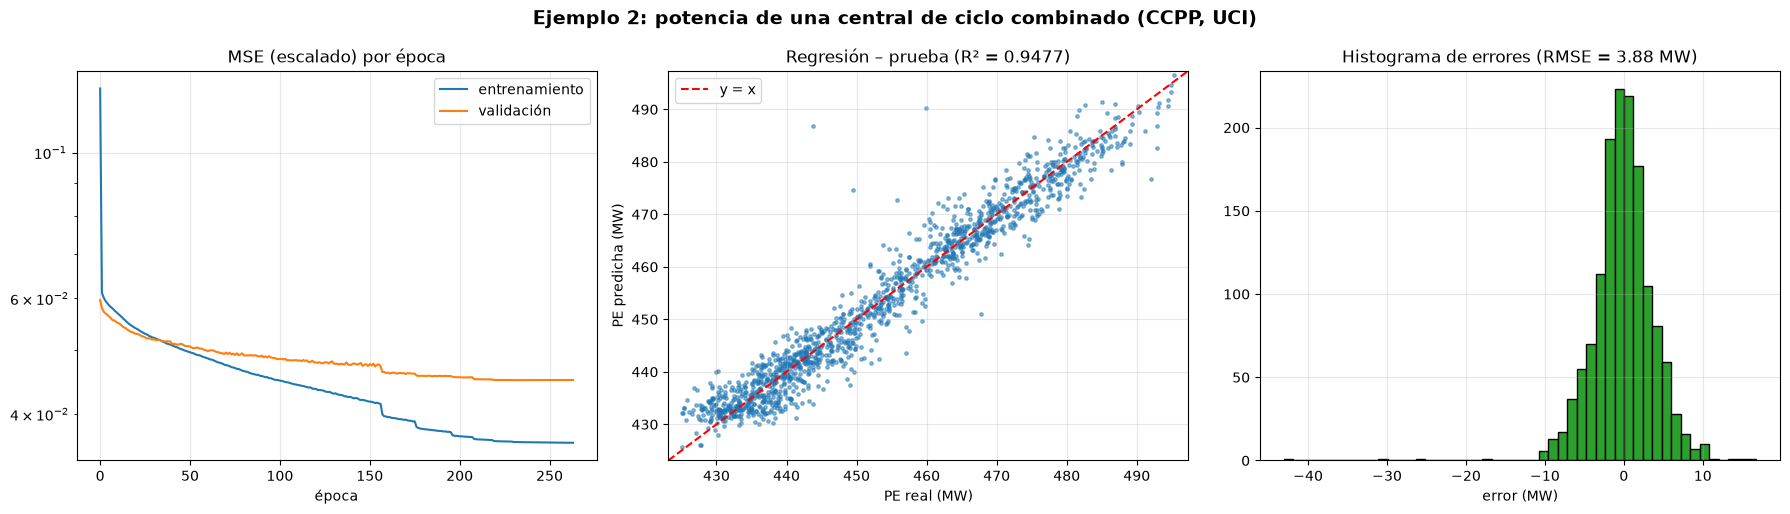

In [6]:
pred = esc_y.inverse_transform(modelo.predict(Xp, verbose=0)).ravel()
real = y_pru.ravel()
mae, rmse, r2 = mean_absolute_error(real, pred), mean_squared_error(real, pred) ** 0.5, r2_score(real, pred)
mape = 100 * np.mean(np.abs((real - pred) / real))
print(f"Prueba -> MAE = {mae:.3f} MW | RMSE = {rmse:.3f} MW | MAPE = {mape:.3f} % | R2 = {r2:.4f}")
print(f"Mejora del RMSE frente a la regresión lineal: {100*(1 - rmse/rmse_lineal):.1f} %")

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
ax[0].plot(hist.history["loss"], label="entrenamiento"); ax[0].plot(hist.history["val_loss"], label="validación")
ax[0].set_yscale("log"); ax[0].set_title("MSE (escalado) por época"); ax[0].set_xlabel("época"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].scatter(real, pred, s=6, alpha=.5)
lim = [real.min() - 2, real.max() + 2]
ax[1].plot(lim, lim, "r--", label="y = x"); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set_title(f"Regresión – prueba (R² = {r2:.4f})"); ax[1].set_xlabel("PE real (MW)"); ax[1].set_ylabel("PE predicha (MW)")
ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].hist(real - pred, bins=50, color="tab:green", edgecolor="k")
ax[2].set_title(f"Histograma de errores (RMSE = {rmse:.2f} MW)"); ax[2].set_xlabel("error (MW)"); ax[2].grid(alpha=.3)
fig.suptitle("Ejemplo 2: potencia de una central de ciclo combinado (CCPP, UCI)", fontsize=14, weight="bold")
fig.tight_layout(); fig.savefig(f"{RESULTADOS}/regresion_ccpp.png", dpi=130); plt.show()

## 6. Uso del modelo: estimar la potencia para condiciones nuevas

In [7]:
def predecir_potencia(at, v, ap, rh):
    x = esc_x.transform(np.array([[at, v, ap, rh]], dtype="float32"))
    return float(esc_y.inverse_transform(modelo.predict(x, verbose=0))[0, 0])

for cond in [(8.0, 40.0, 1015.0, 85.0), (20.0, 55.0, 1012.0, 70.0), (32.0, 70.0, 1008.0, 50.0)]:
    print(f"AT={cond[0]:5.1f} °C  V={cond[1]:5.1f}  AP={cond[2]:7.1f}  RH={cond[3]:4.1f} %  ->  PE = {predecir_potencia(*cond):.2f} MW")

AT=  8.0 °C  V= 40.0  AP= 1015.0  RH=85.0 %  ->  PE = 482.39 MW
AT= 20.0 °C  V= 55.0  AP= 1012.0  RH=70.0 %  ->  PE = 454.19 MW
AT= 32.0 °C  V= 70.0  AP= 1008.0  RH=50.0 %  ->  PE = 432.42 MW
